# Fitting a posteriordb model with BlackJAX

`posteriordb_jax.catalog` holds posteriordb's Stan models translated into modelgami models, with their data loaded. Because every model has the same interface, one sampling function runs on all of them. posteriordb also ships reference posterior draws, which we use to check the fit.

Run `./setup_venv.sh` in this folder once and register the kernel it prints; this notebook uses that kernel ("Python (modelgami)").

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import blackjax
import arviz as az

from posteriordb_jax import catalog

jax.config.update("jax_enable_x64", True)

catalog.list_models()

['earnings-earn_height',
 'earnings-log10earn_height',
 'earnings-logearn_height',
 'earnings-logearn_height_male',
 'earnings-logearn_interaction_z',
 'eight_schools-eight_schools_centered',
 'eight_schools-eight_schools_noncentered',
 'kidiq-kidscore_interaction',
 'kidiq-kidscore_momhs',
 'kidiq-kidscore_momiq',
 'kidiq_with_mom_work-kidscore_mom_work',
 'kilpisjarvi_mod-kilpisjarvi',
 'low_dim_gauss_mix-low_dim_gauss_mix',
 'mesquite-logmesquite_logvolume',
 'mesquite-mesquite',
 'normal_2-normal_mixture',
 'radon_all-radon_pooled',
 'radon_mn-radon_pooled',
 'sblrc-blr',
 'sblri-blr',
 'wells_data-wells_dist',
 'wells_data-wells_dist100_model']

## Load a model

The non-centered eight schools model: `theta_trans` are the standardized school effects, `mu` and `tau` the population mean and scale.

In [2]:
model = catalog.load("eight_schools-eight_schools_noncentered")
print(model.params_pattern)
print("free dimension:", model.free_dim)
model.data

PatternDict(patterns={'theta_trans': ('NumericVectorPattern', {'shape': (8,), 'lb': -inf, 'ub': inf, 'order': 'C'}), 'mu': ('NumericScalarPattern', {'shape': (), 'lb': -inf, 'ub': inf, 'order': 'C'}), 'tau': ('NumericScalarPattern', {'shape': (), 'lb': 0.0, 'ub': inf, 'order': 'C'})})
free dimension: 10


{'y': Array([28,  8, -3,  7, -1,  1, 18, 12], dtype=int64),
 'sigma': Array([15, 10, 16, 11,  9, 11, 10, 18], dtype=int64)}

## A sampler for any model

This function only uses the common interface: `log_density_fn`, `random_params` and `flatten_params`. It returns free draws with shape (chain, draw, dimension).

In [3]:
def nuts(model, key, n_chains=4, n_warmup=1000, n_draws=1000):
    logdensity = model.log_density_fn("joint", params_as="free")

    def run_chain(key):
        init_key, warmup_key, sample_key = jax.random.split(key, 3)
        x_init = model.flatten_params(model.random_params(init_key), free=True)
        warmup = blackjax.window_adaptation(blackjax.nuts, logdensity)
        (state, tuned), _ = warmup.run(warmup_key, x_init, num_steps=n_warmup)
        step = blackjax.nuts(logdensity, **tuned).step

        def one_step(state, key):
            state, info = step(key, state)
            return state, (state.position, info.is_divergent)

        _, (positions, divergent) = jax.lax.scan(one_step, state, jax.random.split(sample_key, n_draws))
        return positions, divergent

    free_draws, divergent = jax.jit(jax.vmap(run_chain))(jax.random.split(key, n_chains))
    return free_draws, int(divergent.sum())

In [4]:
free_draws, n_divergent = nuts(model, jax.random.PRNGKey(0))
print("free draws:", free_draws.shape, "  divergences:", n_divergent)

idata = model.to_arviz(free_draws, params_as="free")
az.summary(idata)

free draws: (4, 1000, 10)   divergences: 3


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,4.5,3.4,-0.99,9.9,3638,2706,1.00,0.056,0.052
tau,3.6,3.2,0.29,9.5,2253,2030,1.00,0.062,0.096
theta_trans[0],0.31,0.98,-1.3,1.9,3814,3347,1.00,0.016,0.014
theta_trans[1],0.12,0.94,-1.4,1.6,4091,2722,1.00,0.015,0.014
theta_trans[2],-0.09,0.96,-1.6,1.5,4387,2749,1.00,0.014,0.015
theta_trans[3],0.06,0.97,-1.5,1.6,5087,3296,1.00,0.014,0.016
theta_trans[4],-0.16,0.95,-1.7,1.4,3495,2662,1.00,0.016,0.016
theta_trans[5],-0.11,0.97,-1.7,1.4,4372,2682,1.00,0.015,0.017
theta_trans[6],0.35,0.96,-1.2,1.9,3994,2845,1.00,0.015,0.016
theta_trans[7],0.08,0.98,-1.5,1.6,4098,2801,1.00,0.015,0.015


## Compare with posteriordb's reference draws

posteriordb stores reference draws by Stan name. For this model they are of `mu`, `tau` and the transformed parameter `theta` (the school effects), so we compute `theta` from our draws too. (For models whose reference draws cover all the parameters, `catalog.reference_draws` returns them already folded, as in the next section.)

In [5]:
from posteriordb_jax.io import load_reference_draws
from posteriordb_jax.stan_names import folded_draws_from_posteriordb
import paragami as pg

draws = jax.vmap(jax.vmap(lambda x: model.fold_params(x, free=True)))(free_draws)
draws["theta"] = draws["theta_trans"] * draws["tau"][..., None] + draws["mu"][..., None]

reference_pattern = pg.PatternDict(theta=pg.NumericVectorPattern(8), mu=pg.NumericScalarPattern(),
                                   tau=pg.NumericScalarPattern(lb=0.0))
reference = folded_draws_from_posteriordb(reference_pattern,
                                          load_reference_draws("eight_schools-eight_schools_noncentered"))

for name in ["mu", "tau", "theta"]:
    ref, ours = np.asarray(reference[name]), np.asarray(draws[name])
    print(f"{name:12s} mean  reference {np.round(ref.mean(axis=(0, 1)), 2)}\n{'':12s}       NUTS      {np.round(ours.mean(axis=(0, 1)), 2)}")

mu           mean  reference 4.41
                   NUTS      4.45
tau          mean  reference 3.6
                   NUTS      3.57
theta        mean  reference [6.15 4.94 3.91 4.8  3.61 4.05 6.32 4.88]
                   NUTS      [6.27 5.08 3.95 4.83 3.65 3.97 6.24 4.94]


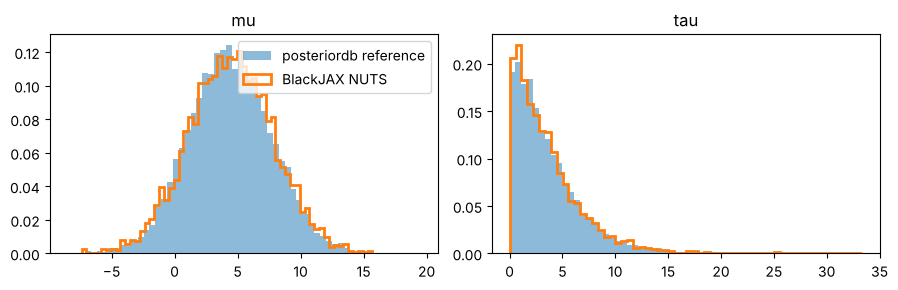

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, name in zip(axes, ["mu", "tau"]):
    ax.hist(np.asarray(reference[name]).ravel(), bins=60, density=True, alpha=0.5, label="posteriordb reference")
    ax.hist(np.asarray(draws[name]).ravel(), bins=60, density=True, histtype="step", lw=2, label="BlackJAX NUTS")
    ax.set_title(name)
axes[0].legend(); plt.tight_layout(); plt.show()

## The same code on several models

Because the interface is shared, a method can be run across the catalog. Here we fit a few models and compare posterior means to the reference draws, measured in reference standard deviations.

In [7]:
names = ["kidiq-kidscore_momiq", "earnings-logearn_height", "mesquite-logmesquite_logvolume", "kilpisjarvi_mod-kilpisjarvi"]
for name in names:
    m = catalog.load(name)
    free_draws, n_div = nuts(m, jax.random.PRNGKey(1), n_warmup=500, n_draws=500)
    ours = jax.vmap(jax.vmap(lambda x: m.fold_params(x, free=True)))(free_draws)
    ref = catalog.reference_draws(name)
    z = max(float(np.max(np.abs(np.asarray(ours[k]).mean(axis=(0, 1)) - np.asarray(ref[k]).mean(axis=(0, 1)))
                         / np.asarray(ref[k]).std(axis=(0, 1)))) for k in ref)
    print(f"{name:35s} free dim {m.free_dim:2d}   divergences {n_div:3d}   max |mean difference| / sd = {z:.3f}")

kidiq-kidscore_momiq                free dim  3   divergences   0   max |mean difference| / sd = 0.081


earnings-logearn_height             free dim  3   divergences   0   max |mean difference| / sd = 0.030


mesquite-logmesquite_logvolume      free dim  3   divergences   0   max |mean difference| / sd = 0.032


kilpisjarvi_mod-kilpisjarvi         free dim  3   divergences   0   max |mean difference| / sd = 0.006


For exchangeable models the ArviZ export includes the pointwise log likelihood, so LOO is one call.

In [8]:
m = catalog.load("kidiq-kidscore_momiq")
free_draws, _ = nuts(m, jax.random.PRNGKey(2), n_warmup=500, n_draws=500)
az.loo(m.to_arviz(free_draws, params_as="free"))

Computed from 2000 posterior samples and 434 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -1878.60    14.53
p_loo        2.93        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)      434  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%